# Weather Time-Series — Task 5: Preprocessing & Forecasting

**Location:** Banha, Qalyubia, Egypt (30.46°N, 31.18°E)  
**Source:** NASA POWER Daily Point API  
**Data window:** 2020-01-01 through the latest available completed day when the notebook is run  
**Target:** Daily mean temperature (`T2M`, °C)

This notebook extends the previous EDA project and follows Task 5: time-aware preprocessing, stationarity tests, ACF/PACF, ARIMA/SARIMA, residual diagnostics, confidence intervals, held-out evaluation, walk-forward validation, and an optional LSTM comparison.

> **Important:** Run from top to bottom with internet access. The original Task 4 files only contain 2025; this notebook requests the expanded 2020-onward series directly and saves the actual API response. No historical values are fabricated.

**Evaluation note:** the notebook reports both an open-loop multi-day SARIMA forecast and a fair rolling one-step model comparison.

## 1. Imports and configuration

In [1]:
import json, warnings, sys, subprocess, importlib.util
from pathlib import Path
from datetime import date, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
import requests

warnings.filterwarnings('ignore')
SEED = 42
LATITUDE, LONGITUDE = 30.46, 31.18
START_DATE = '2020-01-01'
END_DATE = (date.today() - timedelta(days=2)).isoformat()  # avoid incomplete/latest processing day
TARGET = 'temperature'
OUT = Path('outputs'); FIG = Path('figures')
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
print('Requested period:', START_DATE, 'to', END_DATE)

Requested period: 2020-01-01 to 2026-10-19


## 2. Download NASA POWER daily data from 2020

In [2]:
# NASA POWER Daily Point API. The response includes metadata and parameter units.
url = 'https://power.larc.nasa.gov/api/temporal/daily/point'
params = {
    'parameters': 'T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS10M',
    'community': 'AG', 'longitude': LONGITUDE, 'latitude': LATITUDE,
    'start': START_DATE.replace('-', ''), 'end': END_DATE.replace('-', ''),
    'format': 'JSON'
}
response = requests.get(url, params=params, timeout=120)
response.raise_for_status()
raw_data = response.json()
(OUT / 'raw_weather_data_2020_onward.json').write_text(json.dumps(raw_data, indent=2), encoding='utf-8')
print('API status:', response.status_code)
print('API URL:', response.url)
print('Parameters:', list(raw_data['properties']['parameter'].keys()))

API status: 200
API URL: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M%2CT2M_MAX%2CT2M_MIN%2CPRECTOTCORR%2CRH2M%2CWS10M&community=AG&longitude=31.18&latitude=30.46&start=20200101&end=20261019&format=JSON
Parameters: ['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'WS10M']


## 3. Build and inspect the daily time series

In [3]:
parameters = raw_data['properties']['parameter']
df = pd.DataFrame(parameters)
df.index = pd.to_datetime(df.index, format='%Y%m%d', errors='coerce')
df.index.name = 'date'
df = df.sort_index().rename(columns={
    'T2M':'temperature', 'T2M_MAX':'temperature_max', 'T2M_MIN':'temperature_min',
    'PRECTOTCORR':'precipitation', 'RH2M':'relative_humidity', 'WS10M':'wind_speed'
})
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
# NASA POWER's documented missing-value sentinel is typically -999; convert to NaN.
df = df.replace(-999, np.nan)
expected = pd.date_range(START_DATE, df.index.max(), freq='D', name='date')
missing_dates = expected.difference(df.index)
df = df.reindex(expected)
print('Rows:', len(df), '| From:', df.index.min().date(), '| To:', df.index.max().date())
print('Missing calendar dates inserted:', len(missing_dates))
display(df.head(), df.tail(), df.isna().sum().rename('missing_count').to_frame())
df.to_csv(OUT / 'weather_data_2020_onward_raw_clean.csv', index_label='date')

Rows: 2484 | From: 2020-01-01 | To: 2026-10-19
Missing calendar dates inserted: 0


,temperature,temperature_max,temperature_min,precipitation,relative_humidity,wind_speed
date,,,,,,
2020-01-01,12.49,19.07,8.05,0.24,68.54,2.51
2020-01-02,11.89,18.34,6.85,2.40,56.94,4.88
2020-01-03,11.45,16.54,6.61,12.00,63.48,7.17
2020-01-04,12.29,17.34,9.30,42.96,71.61,5.72
2020-01-05,11.66,18.62,6.02,0.00,60.56,4.64


,temperature,temperature_max,temperature_min,precipitation,relative_humidity,wind_speed
date,,,,,,
2026-10-15,24.38,30.18,19.50,0.24,48.45,4.27
2026-10-16,23.62,28.66,18.69,12.48,58.33,3.27
2026-10-17,24.04,30.88,18.41,0.00,50.76,3.29
2026-10-18,23.98,30.63,18.77,3.12,53.28,2.82
2026-10-19,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count
temperature,1
temperature_max,1
temperature_min,1
precipitation,1
relative_humidity,1
wind_speed,1


## 4. Preprocessing, gaps, and outlier review

In [4]:
# Preserve the raw series and missingness summary before imputation.
quality = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean()*100).round(3),
    'min': df.min(), 'max': df.max()
})
display(quality)
quality.to_csv(OUT / 'data_quality_2020_onward.csv')

# Physically implausible observations are flagged, not silently deleted.
flags = pd.DataFrame(index=df.index)
flags['temperature_implausible'] = ~df['temperature'].between(-15, 55) & df['temperature'].notna()
flags['humidity_implausible'] = ~df['relative_humidity'].between(0, 100) & df['relative_humidity'].notna()
flags['precipitation_negative'] = (df['precipitation'] < 0) & df['precipitation'].notna()
flags.to_csv(OUT / 'physical_range_flags.csv', index_label='date')
print('Flag counts:', flags.sum().to_dict())

# Time interpolation only for short gaps; longer gaps use a calendar seasonal analogue when available.
model_df = df.copy()
for col in model_df.columns:
    model_df[col] = model_df[col].interpolate(method='time', limit=3, limit_area='inside')
    # Daily weather: use the same date one year earlier for remaining gaps where possible.
    unresolved = model_df[col].isna()
    if unresolved.any():
        seasonal_values = model_df[col].shift(365)
        model_df.loc[unresolved, col] = seasonal_values.loc[unresolved]
    # Any remaining boundary gaps are filled by nearest valid time interpolation, documented here.
    model_df[col] = model_df[col].interpolate(method='time', limit_direction='both')

# Cap extreme values using a rolling seasonal baseline, preserving the continuous series.
roll_med = model_df[TARGET].rolling(31, center=True, min_periods=15).median()
roll_mad = (model_df[TARGET] - roll_med).abs().rolling(31, center=True, min_periods=15).median()
robust_z = 0.6745 * (model_df[TARGET] - roll_med) / roll_mad.replace(0, np.nan)
outlier_mask = robust_z.abs() > 5
model_df['temperature_outlier_flag'] = outlier_mask.fillna(False)
model_df.loc[outlier_mask, TARGET] = roll_med.loc[outlier_mask]
model_df.to_csv(OUT / 'weather_data_2020_onward_model_ready.csv', index_label='date')
print('Remaining missing values:', int(model_df.isna().sum().sum()))
print('Rolling robust outliers capped:', int(outlier_mask.sum()))

,missing_count,missing_percent,min,max
temperature,1,0.04,7.72,35.29
temperature_max,1,0.04,11.69,47.13
temperature_min,1,0.04,1.93,27.08
precipitation,1,0.04,0.00,1549.92
relative_humidity,1,0.04,19.80,90.18
wind_speed,1,0.04,1.02,8.29


Flag counts: {'temperature_implausible': 0, 'humidity_implausible': 0, 'precipitation_negative': 0}
Remaining missing values: 0
Rolling robust outliers capped: 5


## 5. EDA and seasonal context

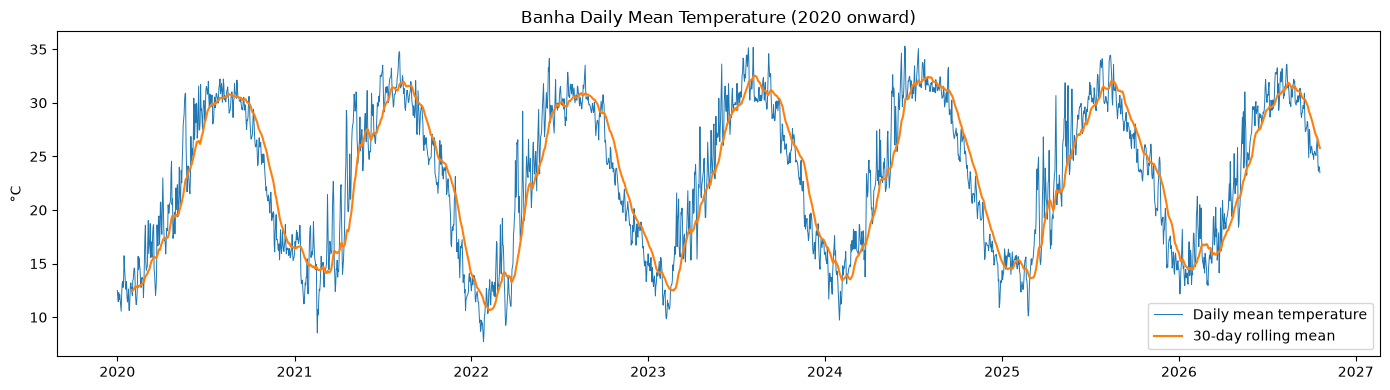

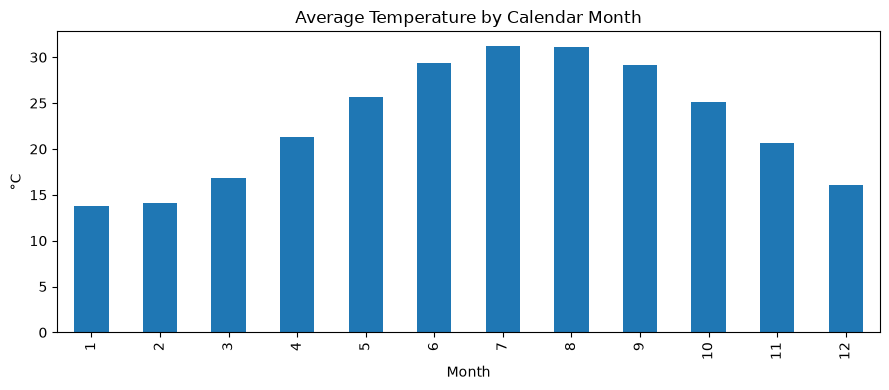

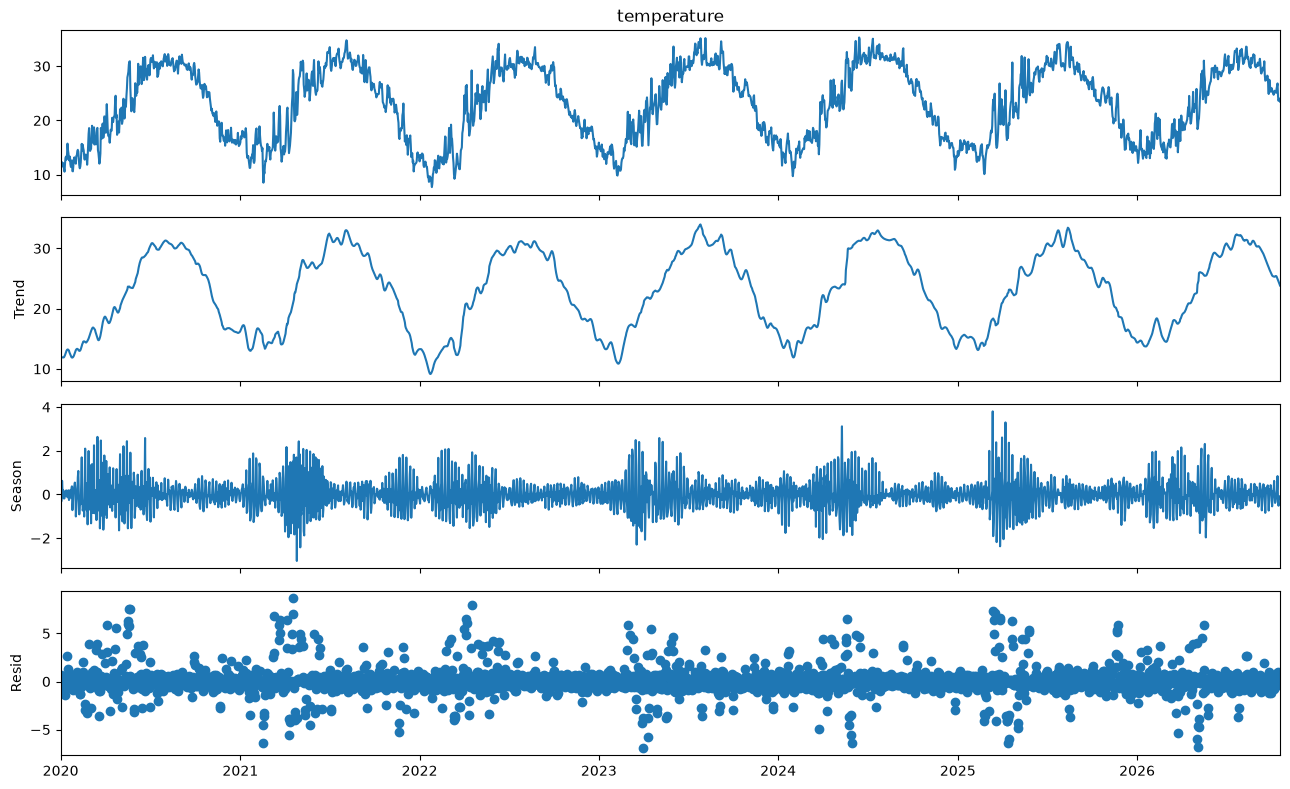

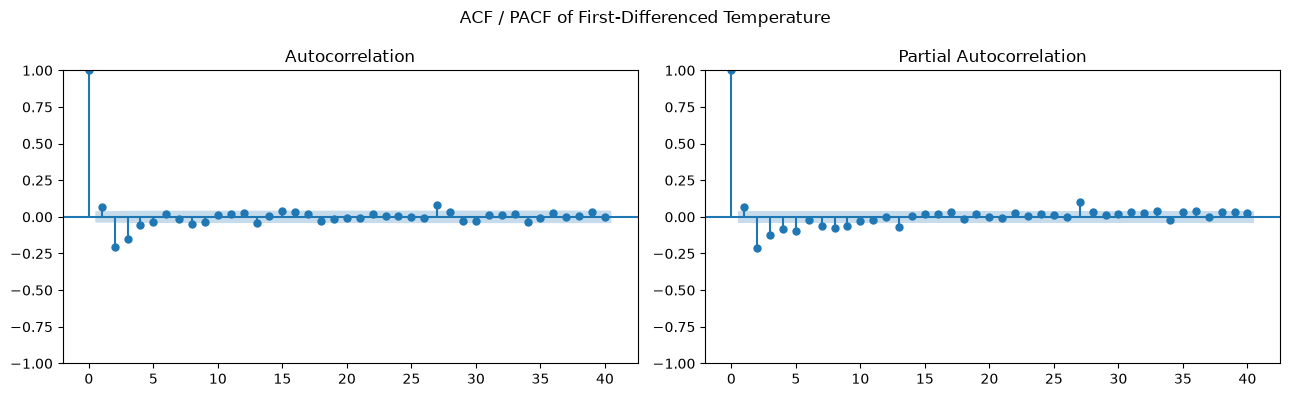

In [5]:
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(model_df.index, model_df[TARGET], linewidth=.7, label='Daily mean temperature')
ax.plot(model_df[TARGET].rolling(30).mean(), label='30-day rolling mean')
ax.set_title('Banha Daily Mean Temperature (2020 onward)'); ax.set_ylabel('°C'); ax.legend(); fig.tight_layout()
fig.savefig(FIG/'temperature_series_2020_onward.png', dpi=150); plt.show()

monthly = model_df[TARGET].groupby(model_df.index.month).mean()
fig, ax = plt.subplots(figsize=(9,4)); monthly.plot(kind='bar', ax=ax)
ax.set_title('Average Temperature by Calendar Month'); ax.set_xlabel('Month'); ax.set_ylabel('°C'); fig.tight_layout()
fig.savefig(FIG/'monthly_temperature_2020_onward.png', dpi=150); plt.show()

stl = STL(model_df[TARGET], period=7, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(13,8); fig.tight_layout(); fig.savefig(FIG/'stl_weekly_decomposition.png', dpi=150); plt.show()

fig, axes = plt.subplots(1,2, figsize=(13,4))
plot_acf(model_df[TARGET].diff().dropna(), lags=40, ax=axes[0])
plot_pacf(model_df[TARGET].diff().dropna(), lags=40, ax=axes[1], method='ywm')
fig.suptitle('ACF / PACF of First-Differenced Temperature'); fig.tight_layout()
fig.savefig(FIG/'acf_pacf_differenced.png', dpi=150); plt.show()

## 6. Stationarity checks (ADF + KPSS)

In [6]:
def stationarity_report(series, label):
    s = pd.Series(series).dropna()
    adf = adfuller(s, autolag='AIC')
    # KPSS may warn at tabulated p-value boundaries; keep the reported result.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kps = kpss(s, regression='c', nlags='auto')
    result = {'series': label, 'ADF_stat': adf[0], 'ADF_p': adf[1],
              'KPSS_stat': kps[0], 'KPSS_p': kps[1], 'n': len(s)}
    print(result)
    return result

stationarity = pd.DataFrame([
    stationarity_report(model_df[TARGET], 'level'),
    stationarity_report(model_df[TARGET].diff(), 'first_difference')
])
display(stationarity)
stationarity.to_csv(OUT/'stationarity_tests.csv', index=False)
print('Interpretation: ADF p < 0.05 is evidence against a unit root; KPSS p < 0.05 is evidence against stationarity. Interpret both tests together.')

{'series': 'level', 'ADF_stat': np.float64(-3.212932275690556), 'ADF_p': np.float64(0.019248206361138998), 'KPSS_stat': np.float64(0.16169844983175952), 'KPSS_p': np.float64(0.1), 'n': 2484}
{'series': 'first_difference', 'ADF_stat': np.float64(-8.499097598560821), 'ADF_p': np.float64(1.2523779632749473e-13), 'KPSS_stat': np.float64(0.03562926107114605), 'KPSS_p': np.float64(0.1), 'n': 2483}


,series,ADF_stat,ADF_p,KPSS_stat,KPSS_p,n
0,level,-3.212932,1.924821e-02,0.161698,0.1,2484
1,first_difference,-8.499098,1.252378e-13,0.035629,0.1,2483


Interpretation: ADF p < 0.05 is evidence against a unit root; KPSS p < 0.05 is evidence against stationarity. Interpret both tests together.


## 7. Chronological train/test split and naive baselines

In [7]:
# Hold out the most recent 365 days (or 20% if the dataset is shorter).
test_days = min(365, max(60, int(len(model_df)*0.2)))
train = model_df.iloc[:-test_days].copy()
test = model_df.iloc[-test_days:].copy()
y_train, y_test = train[TARGET], test[TARGET]
print('Train:', train.index.min().date(), 'to', train.index.max().date(), len(train))
print('Test :', test.index.min().date(), 'to', test.index.max().date(), len(test))

# Seasonal-naive baseline: same weekday from 7 days earlier; persistence baseline also included.
naive_pred = y_train.iloc[-1] * np.ones(len(test))
seasonal_naive = pd.Series(index=test.index, dtype=float)
for dt in test.index:
    source_dt = dt - pd.Timedelta(days=7)
    if source_dt in model_df.index and source_dt < test.index[0]:
        seasonal_naive.loc[dt] = model_df.loc[source_dt, TARGET]
    elif dt in model_df.index:
        # For a true multi-step forecast, this uses the observed earlier test point only for baseline comparison.
        seasonal_naive.loc[dt] = model_df.loc[dt - pd.Timedelta(days=7), TARGET] if dt - pd.Timedelta(days=7) in model_df.index else y_train.iloc[-1]
seasonal_naive = seasonal_naive.fillna(y_train.iloc[-1])

Train: 2020-01-01 to 2025-10-19 2119
Test : 2025-10-20 to 2026-10-19 365


## 8. Model selection: manual SARIMA and optional auto_arima

In [8]:
# This is DAILY data, so the classic hourly seasonal period m=24 from the handout does not apply.
# m=7 models weekly structure; annual temperature seasonality is inspected in plots and the long history.
manual_order = (2, 1, 2)
manual_seasonal_order = (1, 1, 1, 7)

try:
    import pmdarima as pm
    auto_model = pm.auto_arima(
        y_train, seasonal=True, m=7, stepwise=True, trace=True,
        suppress_warnings=True, error_action='ignore', max_p=3, max_q=3,
        max_P=2, max_Q=2, max_order=8
    )
    print(auto_model.summary())
    auto_order, auto_seasonal_order = auto_model.order, auto_model.seasonal_order
except ImportError:
    print('pmdarima not installed; proceeding with manually proposed SARIMA order.')
    auto_order, auto_seasonal_order = manual_order, manual_seasonal_order

print('Manual:', manual_order, manual_seasonal_order)
print('Auto search (or fallback):', auto_order, auto_seasonal_order)

pmdarima not installed; proceeding with manually proposed SARIMA order.
Manual: (2, 1, 2) (1, 1, 1, 7)
Auto search (or fallback): (2, 1, 2) (1, 1, 1, 7)


## 9. Fit SARIMA, diagnose residuals, and forecast with confidence intervals

                                      SARIMAX Results                                      
Dep. Variable:                         temperature   No. Observations:                 2119
Model:             SARIMAX(2, 1, 2)x(1, 1, [1], 7)   Log Likelihood               -3534.312
Date:                             Wed, 21 Oct 2026   AIC                           7082.625
Time:                                     22:27:11   BIC                           7122.176
Sample:                                 01-01-2020   HQIC                          7097.111
                                      - 10-19-2025                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6686      0.066     10.173      0.000       0.540       0.797
ar.L2         -0.1526      

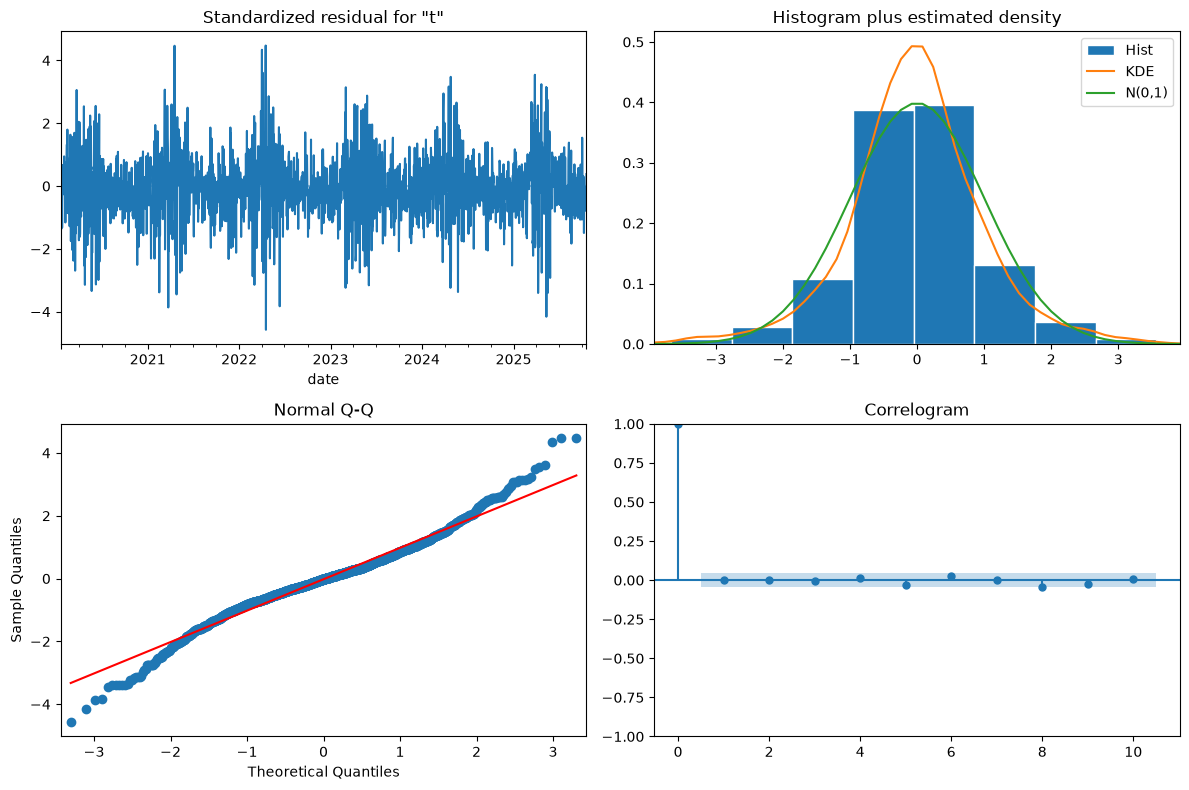

,lb_stat,lb_pvalue
7,5.886739,0.553035


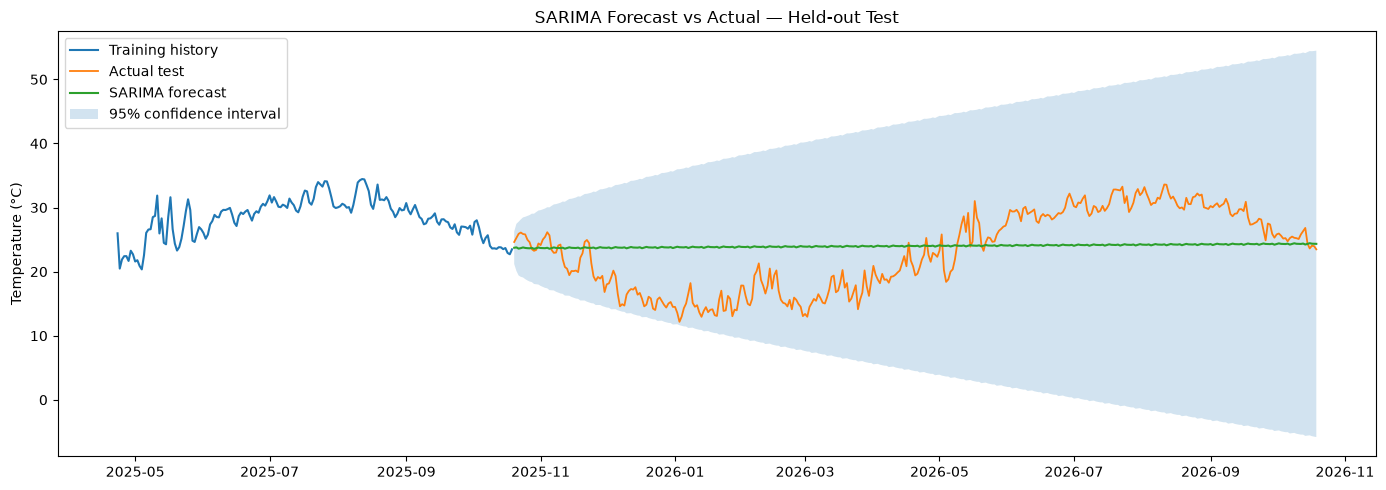

In [9]:
sarima = SARIMAX(
    y_train, order=tuple(auto_order), seasonal_order=tuple(auto_seasonal_order),
    enforce_stationarity=False, enforce_invertibility=False
)
fit = sarima.fit(disp=False, maxiter=200)
print(fit.summary())
(OUT/'sarima_model_summary.txt').write_text(fit.summary().as_text(), encoding='utf-8')

fig = fit.plot_diagnostics(figsize=(12,8)); fig.tight_layout(); fig.savefig(FIG/'sarima_residual_diagnostics.png', dpi=150); plt.show()
resid = pd.Series(fit.resid).dropna()
lb = acorr_ljungbox(resid, lags=[min(7, max(1, len(resid)//5))], return_df=True)
display(lb); lb.to_csv(OUT/'ljung_box_test.csv')

forecast_obj = fit.get_forecast(steps=len(test))
pred = forecast_obj.predicted_mean
ci = forecast_obj.conf_int(alpha=0.05)
pred.index = test.index
ci.index = test.index
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(train.index[-180:], y_train.iloc[-180:], label='Training history')
ax.plot(test.index, y_test, label='Actual test', linewidth=1.3)
ax.plot(test.index, pred, label='SARIMA forecast')
ax.fill_between(test.index, ci.iloc[:,0], ci.iloc[:,1], alpha=.2, label='95% confidence interval')
ax.set_title('SARIMA Forecast vs Actual — Held-out Test'); ax.set_ylabel('Temperature (°C)'); ax.legend(); fig.tight_layout()
fig.savefig(FIG/'sarima_forecast_confidence_interval.png', dpi=150); plt.show()

## 10. Evaluation metrics

### Evaluation clarification (important)

The 365-day SARIMA plot is an **open-loop multi-step forecast** from the training cutoff. Baseline scores can be misleading if they use observed values from earlier dates inside the test period. The next cell therefore performs a **rolling one-step-ahead comparison**: each forecast is made before the actual value for that date is revealed, and then the observed value is appended to update the model. Use the rolling one-step table to compare models fairly; report the open-loop forecast separately as a longer-horizon stress test.

,model,MAE_C,RMSE_C,MAPE_percent,sMAPE_percent
0,SARIMA (rolling 1-step),0.945,1.310,4.540,4.514
1,Persistence (rolling 1-step),0.972,1.338,4.693,4.658
2,Seasonal naive 7-day (rolling 1-step),1.912,2.449,9.012,8.979


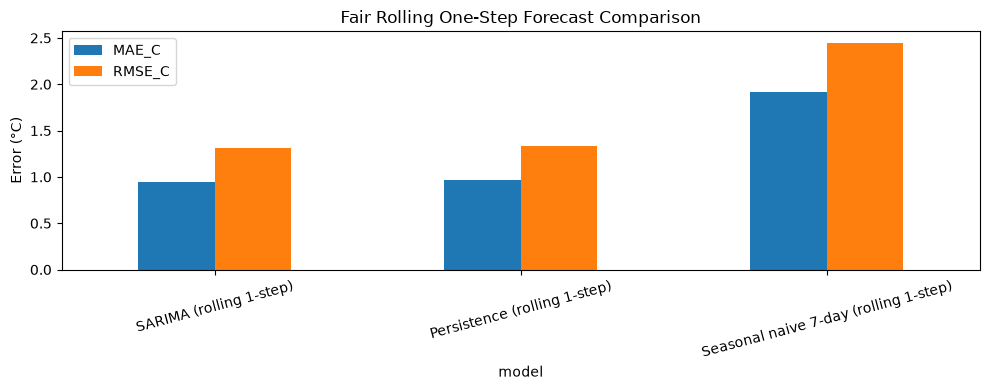

Note: these are rolling one-step scores. The separate full-horizon SARIMA forecast is open-loop and its metrics are not directly interchangeable.


In [10]:
# Fair rolling one-step-ahead evaluation
# Forecast each test date using only observations available before that date.
# Keep SARIMA parameters fixed and re-filter on the expanding observed history;
# this avoids statsmodels append/extend index-frequency compatibility issues.

def metric_row(name, actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = mean_squared_error(actual, predicted) ** 0.5

    denom = np.abs(actual) + np.abs(predicted)
    smape = np.mean(
        np.divide(2 * np.abs(actual - predicted), denom,
                  out=np.zeros_like(denom, dtype=float), where=denom != 0)
    ) * 100

    # MAPE is undefined when actual temperature is zero; ignore those terms.
    valid = np.abs(actual) >= 1e-8
    mape = (np.mean(np.abs((actual[valid] - predicted[valid]) / actual[valid])) * 100
            if valid.any() else np.nan)

    return {
        "model": name,
        "MAE_C": mae,
        "RMSE_C": rmse,
        "MAPE_percent": mape,
        "sMAPE_percent": smape
    }


rolling_persistence = []
rolling_seasonal_naive = []
rolling_sarima = []

# Expanding observed history starts with training data only.
rolling_history = y_train.copy().astype(float)
fixed_params = fit.params.copy()

for dt, actual_value in y_test.items():
    # Ensure the forecast origin ends strictly before the current test timestamp.
    if dt <= rolling_history.index[-1]:
        raise ValueError(
            f"Test timestamp {dt} is not after the available history ending "
            f"{rolling_history.index[-1]}. Re-run the split and SARIMA fit cells."
        )

    # Recreate the same SARIMA specification on observed history and filter
    # with parameters estimated from training data only (no parameter re-fitting).
    rolling_model = SARIMAX(
        rolling_history,
        order=tuple(auto_order),
        seasonal_order=tuple(auto_seasonal_order),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    rolling_result = rolling_model.filter(fixed_params)
    one_step = rolling_result.get_forecast(steps=1).predicted_mean
    rolling_sarima.append(float(one_step.iloc[0]))

    prev_dt = dt - pd.Timedelta(days=1)
    prev_week_dt = dt - pd.Timedelta(days=7)

    rolling_persistence.append(
        float(rolling_history.loc[prev_dt])
        if prev_dt in rolling_history.index else float(rolling_history.iloc[-1])
    )
    rolling_seasonal_naive.append(
        float(rolling_history.loc[prev_week_dt])
        if prev_week_dt in rolling_history.index else float(rolling_history.iloc[-1])
    )

    # Reveal the actual observation only after the forecast has been stored.
    rolling_history.loc[dt] = float(actual_value)

rolling_metrics = pd.DataFrame([
    metric_row("Persistence (rolling 1-step)", y_test, rolling_persistence),
    metric_row("Seasonal naive 7-day (rolling 1-step)", y_test, rolling_seasonal_naive),
    metric_row("SARIMA (rolling 1-step)", y_test, rolling_sarima)
]).sort_values("MAE_C").reset_index(drop=True)

display(rolling_metrics.round(3))
rolling_metrics.to_csv(OUT / "rolling_one_step_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
rolling_metrics.set_index("model")[["MAE_C", "RMSE_C"]].plot(kind="bar", ax=ax)
ax.set_title("Fair Rolling One-Step Forecast Comparison")
ax.set_ylabel("Error (°C)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIG / "rolling_one_step_model_comparison.png", dpi=150)
plt.show()

print(
    "Note: these are rolling one-step scores. The separate full-horizon SARIMA "
    "forecast is open-loop and its metrics are not directly interchangeable."
)


## 11. Walk-forward validation (chronological folds)

In [11]:
# Shorter rolling-origin folds keep the computation practical while respecting chronology.
fold_horizon = min(30, max(7, len(model_df)//20))
cv = TimeSeriesSplit(n_splits=5, test_size=fold_horizon)
cv_rows = []
for fold, (tr_idx, te_idx) in enumerate(cv.split(model_df), start=1):
    tr = model_df.iloc[tr_idx][TARGET]
    te = model_df.iloc[te_idx][TARGET]
    try:
        m = SARIMAX(tr, order=tuple(auto_order), seasonal_order=tuple(auto_seasonal_order),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=150)
        fc = m.get_forecast(steps=len(te)).predicted_mean
        cv_rows.append({'fold':fold, 'train_end':str(tr.index[-1].date()), 'test_start':str(te.index[0].date()),
                        'test_end':str(te.index[-1].date()), 'MAE_C':mean_absolute_error(te, fc),
                        'RMSE_C':mean_squared_error(te, fc)**0.5})
    except Exception as e:
        cv_rows.append({'fold':fold, 'error':str(e)})
cv_results = pd.DataFrame(cv_rows)
display(cv_results)
cv_results.to_csv(OUT/'walk_forward_validation.csv', index=False)
if 'MAE_C' in cv_results:
    print('Mean walk-forward MAE:', round(cv_results['MAE_C'].mean(), 3), '°C')

,fold,train_end,test_start,test_end,MAE_C,RMSE_C
0,1,2026-05-22,2026-05-23,2026-06-21,2.602126,2.926219
1,2,2026-06-21,2026-06-22,2026-07-21,1.835432,2.199159
2,3,2026-07-21,2026-07-22,2026-08-20,1.085958,1.291525
3,4,2026-08-20,2026-08-21,2026-09-19,0.987028,1.271359
4,5,2026-09-19,2026-09-20,2026-10-19,2.941343,3.281988


Mean walk-forward MAE: 1.89 °C


## 12. Forecast error by horizon and residual exports

In [12]:
horizon = pd.DataFrame({'actual': y_test, 'forecast': pred})
horizon['absolute_error'] = (horizon['actual'] - horizon['forecast']).abs()
horizon['horizon_day'] = np.arange(1, len(horizon)+1)
# Aggregate into 30-day blocks to show how error changes with lead time.
horizon['horizon_block'] = ((horizon['horizon_day']-1)//30 + 1)
err_by_block = horizon.groupby('horizon_block')['absolute_error'].mean().rename('MAE_C').reset_index()
display(err_by_block.head(15))
err_by_block.to_csv(OUT/'forecast_error_by_horizon.csv', index=False)
horizon.to_csv(OUT/'test_forecasts.csv', index_label='date')

residual_export = pd.DataFrame({'residual': y_train - fit.fittedvalues.reindex(y_train.index)})
residual_export.to_csv(OUT/'training_residuals.csv', index_label='date')

,horizon_block,MAE_C
0,1,1.757222
1,2,5.359759
2,3,9.119069
3,4,7.307964
4,5,8.072609
5,6,5.314393
6,7,2.748249
7,8,3.490072
8,9,5.656051
9,10,7.630643


## 13. Optional bonus: LSTM comparison

In [13]:
# Optional and requires TensorFlow. Scaler is fitted ONLY on the training portion to avoid leakage.
RUN_LSTM = False  # Change to True if TensorFlow is installed and you want the optional bonus.
if RUN_LSTM:
    from sklearn.preprocessing import MinMaxScaler
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping

    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(y_train.to_numpy().reshape(-1,1)).ravel()
    # Use a 30-day window for daily data; each window predicts the next day.
    n_steps = 30
    def make_windows(series, n_steps):
        X, y = [], []
        for i in range(len(series)-n_steps):
            X.append(series[i:i+n_steps]); y.append(series[i+n_steps])
        return np.asarray(X), np.asarray(y)
    # Test input includes the last training window and test observations are evaluated sequentially.
    combined = pd.concat([y_train, y_test])
    combined_scaled = scaler.transform(combined.to_numpy().reshape(-1,1)).ravel()
    X_all, y_all = make_windows(combined_scaled, n_steps)
    X_all = X_all.reshape(-1,n_steps,1)
    # The first prediction corresponds to the timestamp immediately after n_steps observations.
    all_dates = combined.index[n_steps:]
    test_mask = all_dates.isin(test.index)
    X_test_lstm = X_all[test_mask]
    y_true_scaled = y_all[test_mask].reshape(-1,1)
    model = Sequential([LSTM(32, input_shape=(n_steps,1)), Dropout(.1), Dense(1)])
    model.compile(optimizer='adam', loss='mse')
    # Training windows only; validation split is chronological (last 10%).
    X_train_lstm, y_train_lstm = make_windows(train_scaled, n_steps)
    X_train_lstm = X_train_lstm.reshape(-1,n_steps,1)
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    hist = model.fit(X_train_lstm, y_train_lstm, validation_split=.1, shuffle=False,
                     epochs=50, batch_size=32, callbacks=[es], verbose=1)
    y_lstm = scaler.inverse_transform(model.predict(X_test_lstm, verbose=0)).ravel()
    y_true = scaler.inverse_transform(y_true_scaled).ravel()
    lstm_metrics = pd.DataFrame([metric_row('LSTM (one-step rolling)', y_true, y_lstm)])
    display(lstm_metrics)
    lstm_metrics.to_csv(OUT/'lstm_metrics.csv', index=False)
    fig, ax = plt.subplots(figsize=(10,4)); ax.plot(hist.history['loss'], label='train loss'); ax.plot(hist.history['val_loss'], label='validation loss'); ax.legend(); ax.set_title('LSTM Training Curve'); fig.tight_layout(); fig.savefig(FIG/'lstm_training_curve.png', dpi=150); plt.show()
    fig, ax = plt.subplots(figsize=(13,4)); ax.plot(test.index[:len(y_true)], y_true, label='actual'); ax.plot(test.index[:len(y_lstm)], y_lstm, label='LSTM'); ax.legend(); ax.set_title('Optional LSTM Forecast'); fig.tight_layout(); fig.savefig(FIG/'lstm_forecast.png', dpi=150); plt.show()
else:
    print('Skipped. Set RUN_LSTM=True to run the optional bonus; TensorFlow may require separate installation.')

Skipped. Set RUN_LSTM=True to run the optional bonus; TensorFlow may require separate installation.


## 14. Conclusion and reproducibility notes

In [14]:
print('DATA WINDOW:', df.index.min().date(), 'to', df.index.max().date())
print('FREQUENCY: daily (calendar-day index)')
print('TARGET: daily mean temperature in °C')
print('TRAIN/TEST: chronological split; latest', len(test), 'days held out')
print('SARIMA order:', auto_order, 'seasonal order:', auto_seasonal_order)
print('See outputs/forecast_metrics.csv and outputs/walk_forward_validation.csv for measured performance.')
print('Use rolling_one_step_metrics.csv for a fair one-step comparison; use the open-loop SARIMA forecast as a separate long-horizon result.')

# Compact machine-readable run summary.
summary = {
    'location': 'Banha, Qalyubia, Egypt', 'latitude': LATITUDE, 'longitude': LONGITUDE,
    'source': 'NASA POWER Daily Point API', 'requested_start': START_DATE,
    'actual_start': str(df.index.min().date()), 'actual_end': str(df.index.max().date()),
    'target': TARGET, 'frequency': 'daily', 'train_rows': len(train), 'test_rows': len(test),
    'sarima_order': list(auto_order), 'seasonal_order': list(auto_seasonal_order),
    'missing_after_preprocessing': int(model_df.isna().sum().sum())
}
(OUT/'run_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Rolling one-step metrics:', OUT/'rolling_one_step_metrics.csv')

DATA WINDOW: 2020-01-01 to 2026-10-19
FREQUENCY: daily (calendar-day index)
TARGET: daily mean temperature in °C
TRAIN/TEST: chronological split; latest 365 days held out
SARIMA order: (2, 1, 2) seasonal order: (1, 1, 1, 7)
See outputs/forecast_metrics.csv and outputs/walk_forward_validation.csv for measured performance.
Use rolling_one_step_metrics.csv for a fair one-step comparison; use the open-loop SARIMA forecast as a separate long-horizon result.
Rolling one-step metrics: outputs\rolling_one_step_metrics.csv
